# 2 — The baseline on four systems

**What this notebook establishes.** 8SGE is not a one-off, and it is not the worst
case either. Across the four systems with a scored unperturbed sweep, Boltz-2 fails
in three different ways: the wrong rotamer (8SGE), the wrong cavity 31 Å away
(7FTM), a slot the ligand leaves (8CJG) — and on the fourth it is mostly right
(8JJQ), which is what makes it the harm control.

**What it needs.** `numpy`, `matplotlib`, this repository, and the committed table
`data/baselines/control_poses.csv`. No GPU.

**Read the caveat in `data/baselines/PROVENANCE.md` before quoting a rate.** The
sampling differs between systems: 8SGE and 7FTM vary the model seed, which redraws
the conditioning; 8CJG and 8JJQ vary only the diffusion noise under one fixed
conditioning. Rates are solid within a system, loose across them.


In [1]:
import csv, sys, pathlib, collections

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'src' / 'cofolding_tts').is_dir())
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import matplotlib.pyplot as plt

rows = list(csv.DictReader((ROOT / 'data' / 'baselines' / 'control_poses.csv').open()))
rmsd = {}
for r in rows:
    rmsd.setdefault(r['pdb'], []).append(float(r['ligand_rmsd_angstrom']))
rmsd = {k: np.array(v) for k, v in rmsd.items()}
fam = {r['pdb']: r for r in
       csv.DictReader((ROOT / 'data' / 'baselines' / 'systems.csv').open())}

print(f'{len(rows)} unperturbed draws across {len(rmsd)} systems')
print({k: len(v) for k, v in sorted(rmsd.items())})

97 unperturbed draws across 4 systems
{'7ftm': 32, '8cjg': 20, '8jjq': 20, '8sge': 25}


## What each system fails at

The 2 Å line is the usual pose-accuracy threshold, and it is the only criterion
that means the same thing on all four. Each system also has its own failure mode,
which is what the last column names — one number cannot carry that.


In [2]:
FAILURE = {
    '8sge': 'the wrong rotamer of one hindered bond; same pocket, ~6 A out',
    '8cjg': 'the indole leaves its hydrophobic slot',
    '7ftm': 'the wrong cavity entirely, ~31 A away',
    '8jjq': 'mostly right; this is the harm control',
}
ORDER = ['8sge', '7ftm', '8cjg', '8jjq']

print(f"{'system':>7}  {'familiar':>8}  {'n':>3}  {'<2 A':>7}  {'median':>7}   failure mode")
for pdb in ORDER:
    v = rmsd[pdb]
    hits = int((v < 2).sum())
    print(f'{pdb.upper():>7}  {float(fam[pdb]["familiarity_0_to_100"]):8.1f}  {len(v):3d}  '
          f'{hits:3d}/{len(v):<3d}  {np.median(v):6.2f} A   {FAILURE[pdb]}')

print()
for pdb in ORDER:
    f = fam[pdb]
    print(f'{pdb.upper():>7}  closest system released before the {f["structural_training_cutoff"]} '
          f'cutoff: {f["closest_pre_cutoff_system"]} ({f["closest_system_release_date"]})')

 system  familiar    n     <2 A   median   failure mode
   8SGE      29.5   25    1/25     6.76 A   the wrong rotamer of one hindered bond; same pocket, ~6 A out
   7FTM       0.0   32    0/32    31.18 A   the wrong cavity entirely, ~31 A away
   8CJG       0.0   20    7/20     5.83 A   the indole leaves its hydrophobic slot
   8JJQ       0.0   20   18/20     1.70 A   mostly right; this is the harm control

   8SGE  closest system released before the 2021-09-30 cutoff: 6do5__1__1.A__1.D (2018-12-19)
   7FTM  closest system released before the 2021-09-30 cutoff: 5vdt__1__1.A__1.D (2017-09-27)
   8CJG  closest system released before the 2021-09-30 cutoff: 3f8r__1__1.A_1.B__1.E (2009-01-13)
   8JJQ  closest system released before the 2021-09-30 cutoff: 7br3__1__1.A__1.L (2020-10-07)


## The shape of a failure, not just its rate

A model that is diffusely imprecise and a model that is confidently in the wrong
place have the same mean error and need opposite fixes. The spread says which one
this is: on three of the four, the draws pile up tightly around a single wrong
answer rather than scattering.


In [3]:
print(f"{'system':>7}  {'spread of the draws':>20}   reading")
for pdb in ORDER:
    v = rmsd[pdb]
    iqr = np.percentile(v, 75) - np.percentile(v, 25)
    tight = 'one reproducible answer' if iqr < 1.0 else 'draws disagree with each other'
    print(f'{pdb.upper():>7}  IQR {iqr:5.2f} A, SD {v.std():5.2f} A   {tight}')

 system   spread of the draws   reading
   8SGE  IQR  0.11 A, SD  1.17 A   one reproducible answer
   7FTM  IQR  0.17 A, SD  0.22 A   one reproducible answer
   8CJG  IQR  4.95 A, SD  2.38 A   draws disagree with each other
   8JJQ  IQR  0.10 A, SD  0.60 A   one reproducible answer


wrote results/figures/nb02_baselines.png


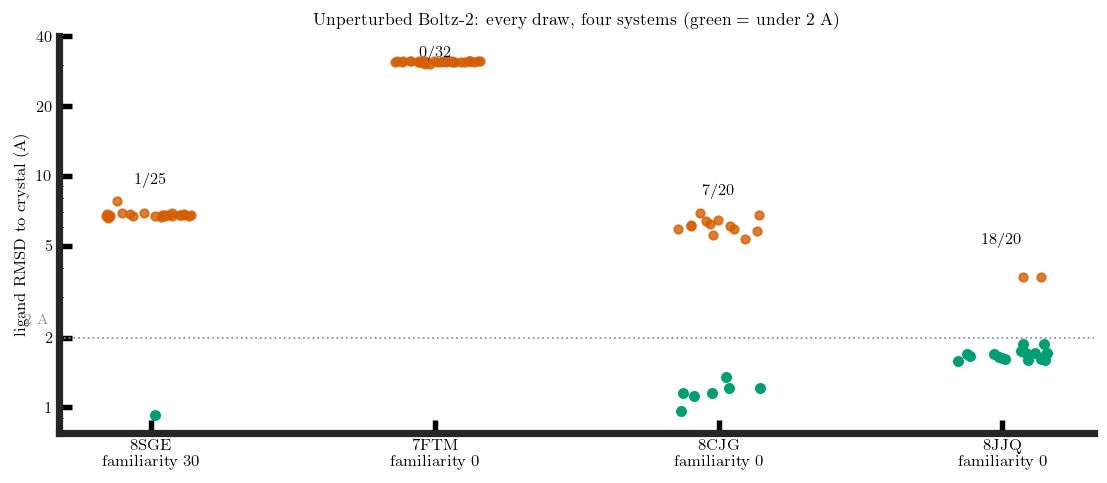

In [4]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.labelsize': 9, 'axes.titlesize': 9.5,
                     'xtick.labelsize': 9, 'ytick.labelsize': 8.5})
fig, ax = plt.subplots(figsize=(8.4, 3.6), dpi=130, constrained_layout=True)
GREEN, ORANGE, GREY = '#009e73', '#d55e00', '#8a93a0'
rng = np.random.default_rng(0)

for i, pdb in enumerate(ORDER):
    v = rmsd[pdb]
    jitter = rng.uniform(-0.16, 0.16, len(v))
    good = v < 2
    ax.scatter(np.full(len(v), i)[~good] + jitter[~good], v[~good], s=22,
               color=ORANGE, alpha=.8)
    ax.scatter(np.full(len(v), i)[good] + jitter[good], v[good], s=26, color=GREEN)
    ax.text(i, v.max() + 1.4, f'{int(good.sum())}/{len(v)}', ha='center', fontsize=8.5)

ax.axhline(2.0, color=GREY, lw=1.0, ls=':')
ax.text(-0.45, 2.3, '2 A', fontsize=8, color=GREY)
ax.set_yscale('log')
ax.set_yticks([1, 2, 5, 10, 20, 40]); ax.set_yticklabels(['1', '2', '5', '10', '20', '40'])
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([f'{p.upper()}\nfamiliarity {float(fam[p]["familiarity_0_to_100"]):.0f}'
                    for p in ORDER])
ax.set_ylabel('ligand RMSD to crystal (A)')
ax.set_title('Unperturbed Boltz-2: every draw, four systems  '
             '(green = under 2 A)', fontsize=9.5)
ax.spines[['top', 'right']].set_visible(False)
out = ROOT / 'results' / 'figures' / 'nb02_baselines.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## What this fixes for the notebooks that follow

- **Familiarity does not explain any of this.** The score is how much a target
  looks like the closest thing released before the training cutoff, on 0-100.
  Three of the four sit at **0.0** — including 8JJQ, where the model is right
  18 times in 20 — and the one system with real familiarity, 8SGE at **29.5**,
  is the one it gets wrong 24 times in 25. Whatever is failing here is not
  unfamiliarity with the fold or the pocket.
- **8SGE and 7FTM fail reproducibly**, not noisily: the draws agree with each other
  and disagree with the crystal. Sampling harder does not fix that; the model has
  to be moved somewhere else.
- **8JJQ is mostly right.** Any intervention has to be run here too, because an
  intervention that helps where the model is wrong and is never tested where it is
  right has not been tested at all. On 8JJQ destroying `s_lig` takes 90% to 68%.
- **No baseline is claimed for 8AM2, 8ATB, 8RDK or 8PFL.** 8AM2 has no single rate —
  it is right under one conditioning and wrong under another, which is why it is on
  the watchlist; the others are unrun or used only as a null. See
  `data/baselines/PROVENANCE.md`.

Next: **3 — destroying the ligand rows of the trunk**, measured against these
numbers and against 8JJQ in particular.
